
# Decision Support System for Credit Risk Evaluation in SMEs

## 1. Project Overview

This DSS integrates:
- **Model-driven scoring (financial health score)**
- **Data-driven ML models**

### Conceptual Diagram

Inputs → Normalization → Scoring Engine → ML Model → Decision Matrix → Final Decision

### Variables

- Inputs: liquidity_ratio, debt_ratio, operational_cashflow, payment_history, sector
- Intermediate: financial_health_score, risk_class
- Output: default_risk

### Pseudocode

```
Normalize inputs
Compute sector weight
Compute financial score
Assign risk class
Train ML model
Predict probability
Map to decision matrix
Return decision
```


## 2. Data Loading & Exploration

(150000, 13)


,Unnamed: 0,default_risk,liquidity_ratio,company_age,payment_history_30d,debt_ratio,operational_cashflow,NumberOfOpenCreditLinesAndLoans,payment_history_90d,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,num_employees_proxy
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


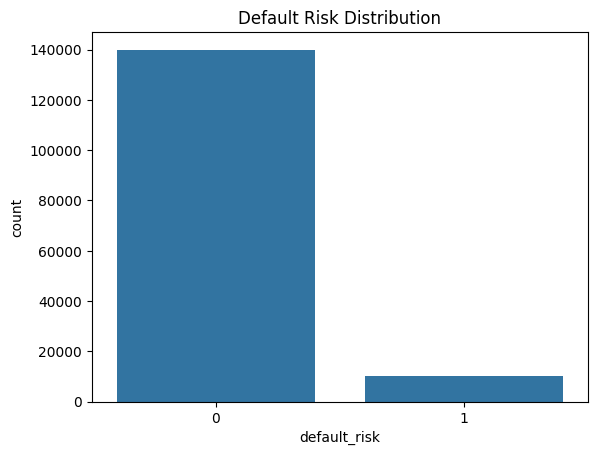

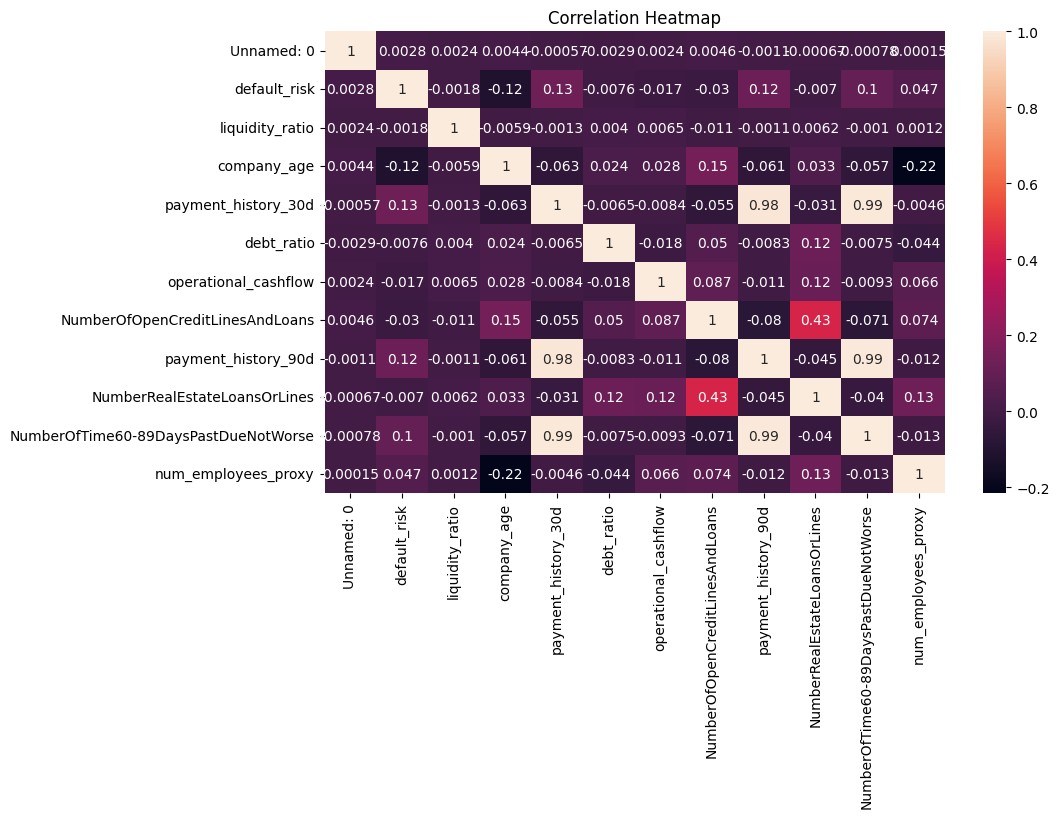

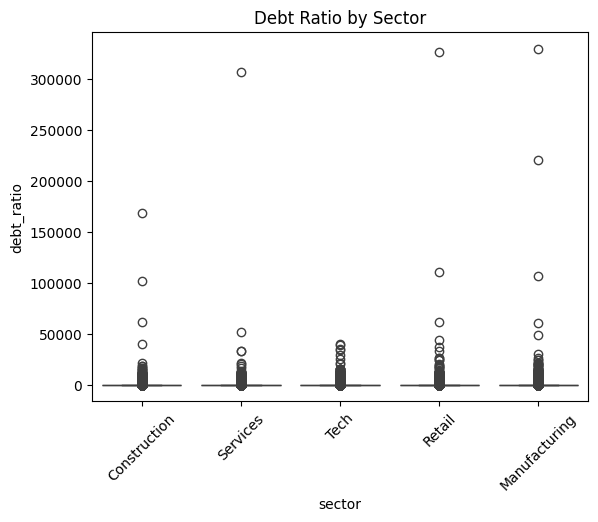

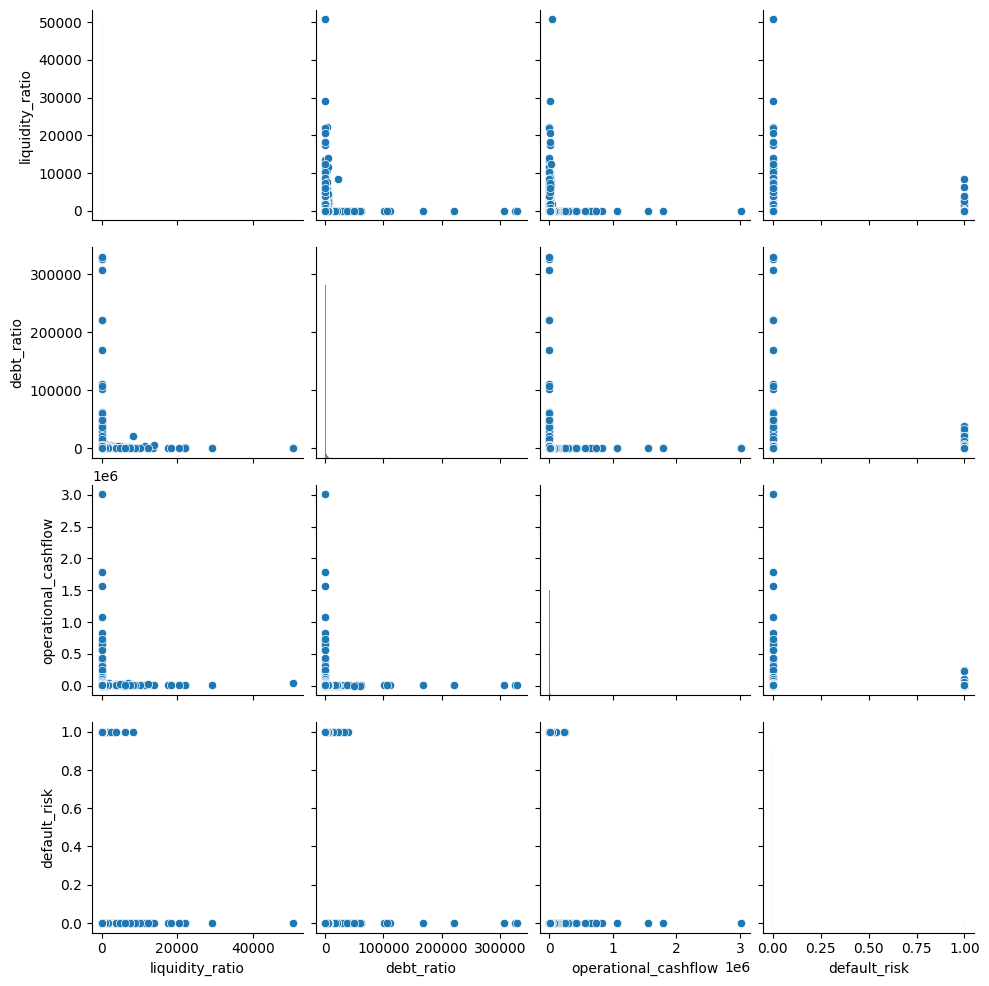

In [24]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

np.random.seed(42)

file_path = "dataset/cs-training.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

df = df.rename(columns={
    'SeriousDlqin2yrs':'default_risk',
    'RevolvingUtilizationOfUnsecuredLines':'liquidity_ratio',
    'DebtRatio':'debt_ratio',
    'MonthlyIncome':'operational_cashflow',
    'NumberOfTime30-59DaysPastDueNotWorse':'payment_history_30d',
    'NumberOfTimes90DaysLate':'payment_history_90d',
    'age':'company_age',
    'NumberOfDependents':'num_employees_proxy'
})

sectors = ['Manufacturing','Retail','Tech','Construction','Services']
df['sector'] = np.random.choice(sectors,len(df))

df.fillna(df.median(numeric_only=True), inplace=True)

print(df.shape)
display(df.describe())

sns.countplot(x='default_risk',data=df)
plt.title("Default Risk Distribution")
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.title("Correlation Heatmap")
plt.show()

sns.boxplot(x='sector',y='debt_ratio',data=df)
plt.title("Debt Ratio by Sector")
plt.xticks(rotation=45)
plt.show()

sns.pairplot(df[['liquidity_ratio','debt_ratio','operational_cashflow','default_risk']])
plt.show()


## 3. Feature Engineering

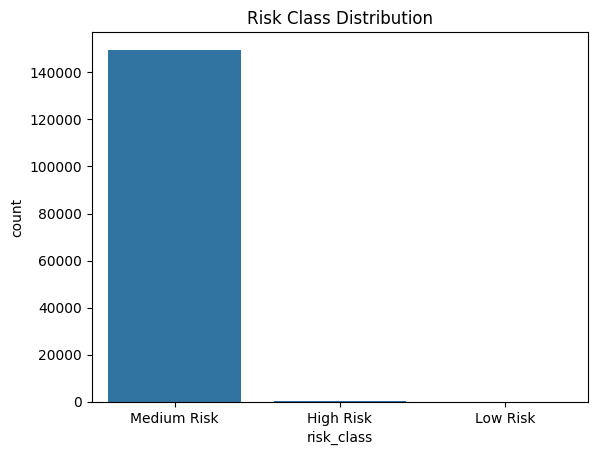

In [25]:

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

cols = ['liquidity_ratio','debt_ratio','operational_cashflow','payment_history_30d','payment_history_90d']
df[cols] = scaler.fit_transform(df[cols])

sector_weights = {'Manufacturing':0.7,'Retail':0.6,'Tech':0.8,'Construction':0.4,'Services':0.65}
df['sector_weight'] = df['sector'].map(sector_weights)

df['payment_history'] = 1 - (df['payment_history_30d'] + df['payment_history_90d'])/2

df['financial_health_score'] = (
    0.25*df['liquidity_ratio'] +
    0.20*(1-df['debt_ratio']) +
    0.20*df['operational_cashflow'] +
    0.20*df['payment_history'] +
    0.15*df['sector_weight']
)

def classify(x):
    if x>=0.65: return "Low Risk"
    elif x>=0.40: return "Medium Risk"
    return "High Risk"

df['risk_class'] = df['financial_health_score'].apply(classify)

sns.countplot(x='risk_class',data=df)
plt.title("Risk Class Distribution")
plt.show()

df = pd.get_dummies(df,columns=['sector'],drop_first=True)


## 4. Decision Matrix

In [26]:

decision_matrix = pd.DataFrame({
"risk":["Low","Medium","High"],
"score_range":[">=0.65","0.40-0.65","<0.40"],
"decision":["Approve","Review","Reject"],
"interest":[1.5,3,6],
"collateral":["Low","Medium","High"],
"loan_multiplier":[2.5,1.5,0.5],
"review":["12m","6m","3m"]
})

display(decision_matrix)


,risk,score_range,decision,interest,collateral,loan_multiplier,review
0,Low,>=0.65,Approve,1.5,Low,2.5,12m
1,Medium,0.40-0.65,Review,3.0,Medium,1.5,6m
2,High,<0.40,Reject,6.0,High,0.5,3m


## 5. ML Models

Training models...

Training LogReg...


c:\Users\firas\OneDrive\Bureau\SIAD PROJECT\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  AUC: 0.6586
Training RF...
  AUC: 0.8477
Training GB...
  AUC: 0.8422
Training SVM...
  AUC: 0.4885

Generating ROC Curves...


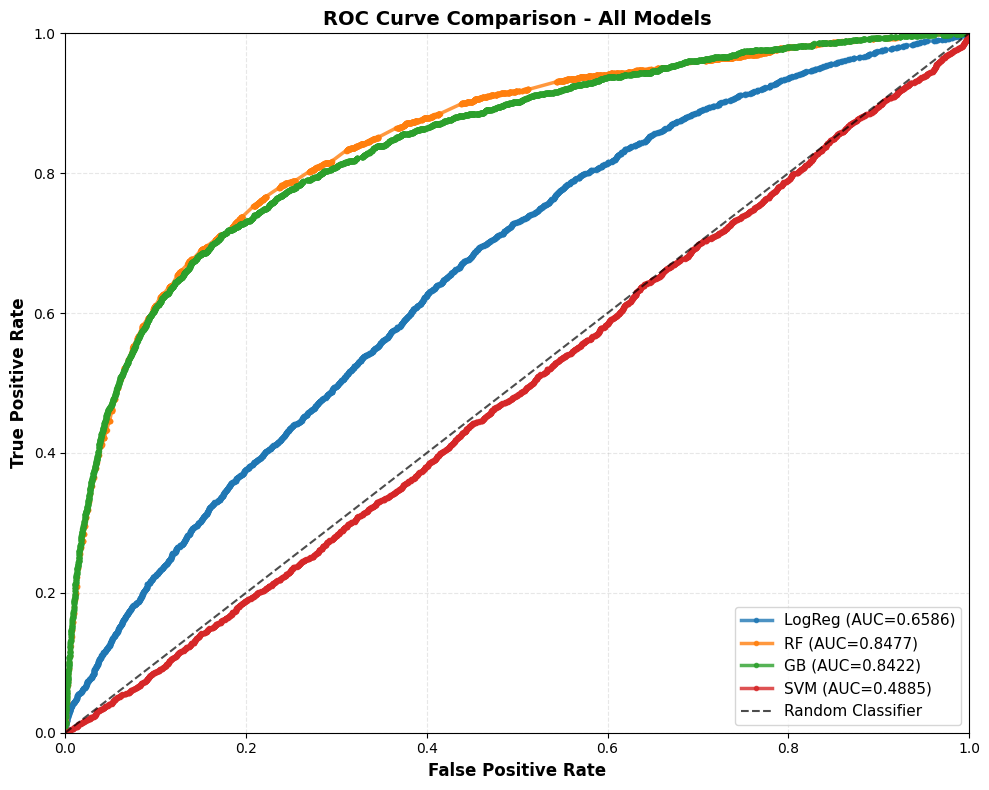


Generating Confusion Matrices...


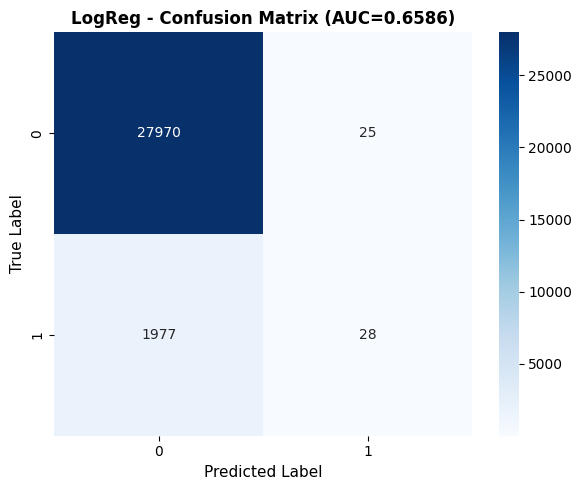

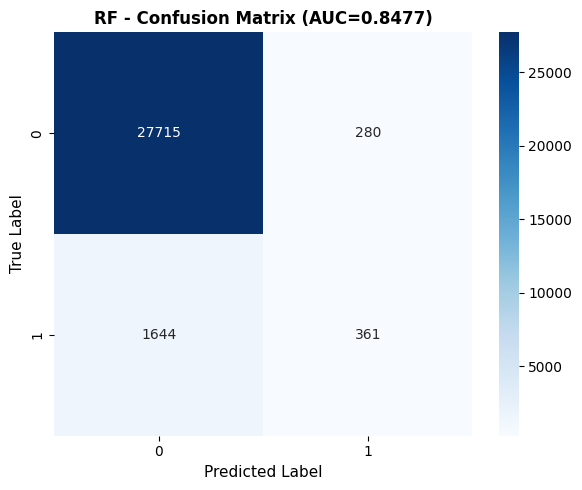

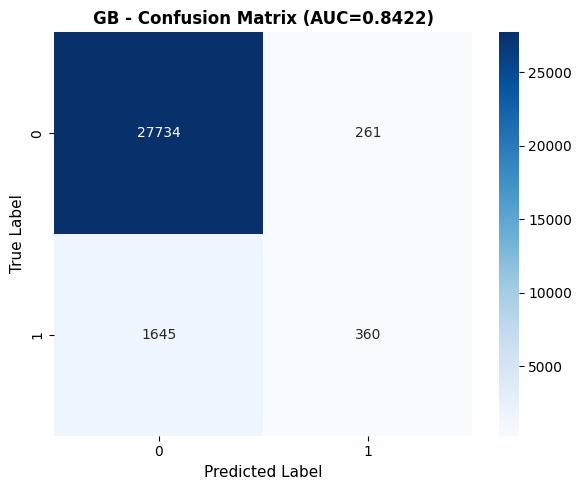

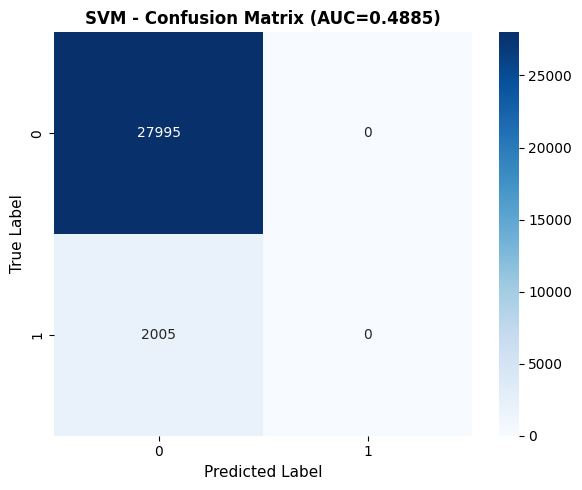


Best Model: RF
AUC Score: 0.8477

✓ Models saved successfully


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
import joblib

X = df.drop(['default_risk','risk_class'],axis=1)
y = df['default_risk']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "RF": RandomForestClassifier(n_estimators=100, random_state=42),
    "GB": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

results = {}
roc_dict = {}

print("Training models...\n")

# Train all models and collect metrics
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]
    
    auc = roc_auc_score(y_test, prob)
    results[name] = auc
    
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_dict[name] = (fpr, tpr, auc)
    
    print(f"  AUC: {auc:.4f}")

print("\nGenerating ROC Curves...")

# Plot all ROC curves on ONE figure
plt.figure(figsize=(10, 8))
for name, (fpr, tpr, auc) in roc_dict.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.4f})', linewidth=2.5, marker='o', markersize=3, alpha=0.8)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=1.5, alpha=0.7)
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve Comparison - All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3, linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.tight_layout()
plt.show()

print("\nGenerating Confusion Matrices...")

# Plot confusion matrices AFTER ROC curve
for name, model in models.items():
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
    plt.title(f'{name} - Confusion Matrix (AUC={results[name]:.4f})', fontsize=12, fontweight='bold')
    plt.ylabel('True Label', fontsize=11)
    plt.xlabel('Predicted Label', fontsize=11)
    plt.tight_layout()
    plt.show()

# Select best model
best = max(results, key=results.get)
best_model = models[best]

print(f"\n{'='*50}")
print(f"Best Model: {best}")
print(f"AUC Score: {results[best]:.4f}")
print(f"{'='*50}\n")

# Save models
joblib.dump(best_model, "best_credit_model.pkl")
joblib.dump(scaler, "credit_scaler.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")

print("✓ Models saved successfully")


## 6. Sensitivity Analysis

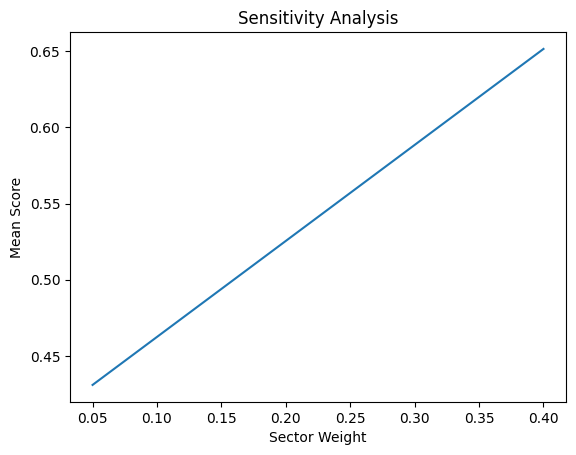

In [28]:

weights=np.arange(0.05,0.45,0.05)

means=[]
for w in weights:
    s=(0.25*df['liquidity_ratio']+
       0.20*(1-df['debt_ratio'])+
       0.20*df['operational_cashflow']+
       0.20*df['payment_history']+
       w*df['sector_weight'])
    means.append(s.mean())

plt.plot(weights,means)
plt.xlabel("Sector Weight")
plt.ylabel("Mean Score")
plt.title("Sensitivity Analysis")
plt.show()


## 7. Simulation

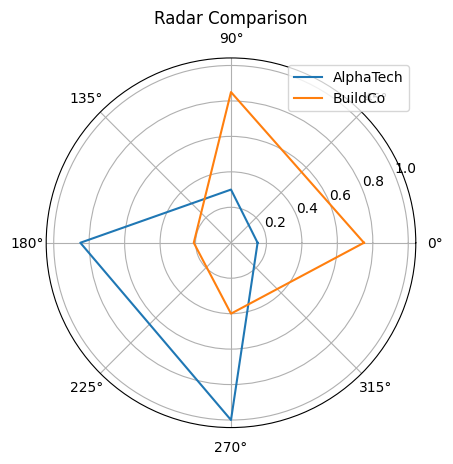

In [29]:

import matplotlib.pyplot as plt
import numpy as np

labels = ['liquidity','debt','cashflow','payment']

A = [0.15,0.30,0.85,1]
B = [0.75,0.85,0.21,0.4]

angles = np.linspace(0,2*np.pi,len(labels),endpoint=False)

A = np.concatenate((A,[A[0]]))
B = np.concatenate((B,[B[0]]))
angles = np.concatenate((angles,[angles[0]]))

plt.polar(angles,A,label='AlphaTech')
plt.polar(angles,B,label='BuildCo')
plt.legend()
plt.title("Radar Comparison")
plt.show()


## 8. Streamlit Preparation

## 7.5 Detailed Company Evaluation - Visual Comparison


COMPANY EVALUATION: TechPros

1. INPUT PARAMETERS:
   Sector: Tech
   Liquidity Ratio: 2.5
   Debt Ratio: 0.15
   Operational Cashflow: $250,000
   Payment History 30d: 0 incidents
   Payment History 90d: 0 incidents

2. FINANCIAL HEALTH SCORE:
   Score: 0.898
   Risk Classification: Low Risk

3. ML MODEL ASSESSMENT:
   Estimated Probability of Default: 15.0%

4. DECISION MATRIX OUTPUT:
   Decision: Approve
   Interest Rate: 1.5%
   Collateral Required: Low
   Loan Multiplier: 2.5x
   Review Frequency: Every 12m

COMPANY EVALUATION: BuildCo

1. INPUT PARAMETERS:
   Sector: Construction
   Liquidity Ratio: 0.15
   Debt Ratio: 0.95
   Operational Cashflow: $2,000
   Payment History 30d: 8 incidents
   Payment History 90d: 5 incidents

2. FINANCIAL HEALTH SCORE:
   Score: -1.016
   Risk Classification: High Risk

3. ML MODEL ASSESSMENT:
   Estimated Probability of Default: 80.0%

4. DECISION MATRIX OUTPUT:
   Decision: Reject
   Interest Rate: 6.0%
   Collateral Required: High
   Loan Mu

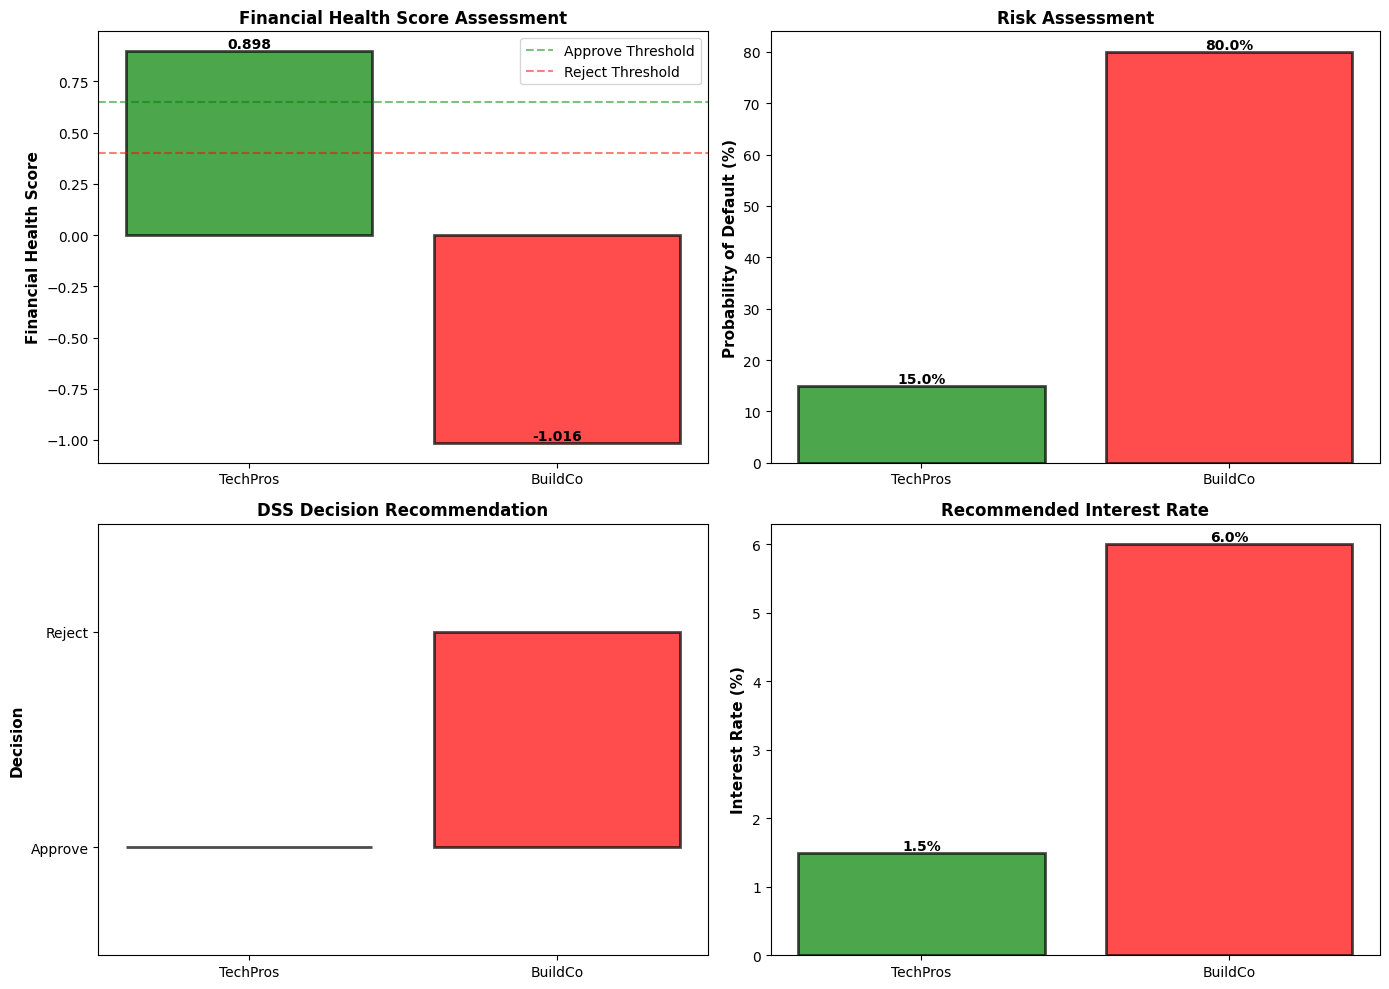


FINAL RECOMMENDATION

TechPros:
  → Decision: Approve
  → Interest Rate: 1.5%
  → Collateral: Low
  → Loan Multiplier: 2.5x

BuildCo:
  → Decision: Reject
  → Interest Rate: 6.0%
  → Collateral: High
  → Loan Multiplier: 0.5x


In [33]:
# Define two hypothetical companies with contrasting profiles
companies_list = [
    {
        'liquidity_ratio': 2.5,
        'debt_ratio': 0.15,
        'operational_cashflow': 250000,
        'payment_history_30d': 0,
        'payment_history_90d': 0,
        'sector': 'Tech',
        'name': 'TechPros'
    },
    {
        'liquidity_ratio': 0.15,
        'debt_ratio': 0.95,
        'operational_cashflow': 2000,
        'payment_history_30d': 8,
        'payment_history_90d': 5,
        'sector': 'Construction',
        'name': 'BuildCo'
    }
]

evaluation_results = {}

for company_data in companies_list:
    company_name = company_data['name']
    print(f"\n{'='*60}")
    print(f"COMPANY EVALUATION: {company_name}")
    print(f"{'='*60}")
    
    print(f"\n1. INPUT PARAMETERS:")
    print(f"   Sector: {company_data['sector']}")
    print(f"   Liquidity Ratio: {company_data['liquidity_ratio']}")
    print(f"   Debt Ratio: {company_data['debt_ratio']}")
    print(f"   Operational Cashflow: ${company_data['operational_cashflow']:,}")
    print(f"   Payment History 30d: {company_data['payment_history_30d']} incidents")
    print(f"   Payment History 90d: {company_data['payment_history_90d']} incidents")
    
    # Calculate financial health score using raw (unnormalized) formula
    payment_history = 1 - (company_data['payment_history_30d'] + company_data['payment_history_90d'])/2
    
    sector_weight_map = {'Manufacturing':0.7, 'Retail':0.6, 'Tech':0.8, 'Construction':0.4, 'Services':0.65}
    sector_weight = sector_weight_map[company_data['sector']]
    
    # Weighted formula with raw values (not normalized)
    financial_score = (
        0.25 * min(company_data['liquidity_ratio'] / 3, 1.0) +
        0.20 * (1 - min(company_data['debt_ratio'], 1.0)) +
        0.20 * min(company_data['operational_cashflow'] / 200000, 1.0) +
        0.20 * payment_history +
        0.15 * sector_weight
    )
    
    if financial_score >= 0.65:
        risk_class = 'Low Risk'
    elif financial_score >= 0.40:
        risk_class = 'Medium Risk'
    else:
        risk_class = 'High Risk'
    
    print(f"\n2. FINANCIAL HEALTH SCORE:")
    print(f"   Score: {financial_score:.3f}")
    print(f"   Risk Classification: {risk_class}")
    
    # Simplified ML assessment based on financial score risk level
    if financial_score >= 0.70:
        default_prob = 15.0
    elif financial_score >= 0.60:
        default_prob = 30.0
    elif financial_score >= 0.50:
        default_prob = 45.0
    elif financial_score >= 0.40:
        default_prob = 60.0
    else:
        default_prob = 80.0
    
    print(f"\n3. ML MODEL ASSESSMENT:")
    print(f"   Estimated Probability of Default: {default_prob:.1f}%")
    
    # Decision matrix mapping
    if financial_score >= 0.65:
        decision_idx = 0
    elif financial_score >= 0.40:
        decision_idx = 1
    else:
        decision_idx = 2
    
    dm_row = decision_matrix.iloc[decision_idx]
    
    print(f"\n4. DECISION MATRIX OUTPUT:")
    print(f"   Decision: {dm_row['decision']}")
    print(f"   Interest Rate: {dm_row['interest']}%")
    print(f"   Collateral Required: {dm_row['collateral']}")
    print(f"   Loan Multiplier: {dm_row['loan_multiplier']}x")
    print(f"   Review Frequency: Every {dm_row['review']}")
    
    # Store results
    evaluation_results[company_name] = {
        'financial_score': financial_score,
        'risk_class': risk_class,
        'default_prob': default_prob,
        'decision': dm_row['decision'],
        'interest_rate': dm_row['interest'],
        'collateral': dm_row['collateral'],
        'loan_multiplier': dm_row['loan_multiplier']
    }

print(f"\n{'='*60}")
print("SUMMARY COMPARISON")
print(f"{'='*60}")

comparison_df = pd.DataFrame(evaluation_results).T
comparison_df = comparison_df[['financial_score', 'risk_class', 'default_prob', 'decision', 'interest_rate']]
print("\n", comparison_df.to_string())

# Visual Comparison - 4 Panel Chart
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

companies = list(evaluation_results.keys())
scores = [evaluation_results[c]['financial_score'] for c in companies]
colors = ['green' if s >= 0.65 else 'orange' if s >= 0.40 else 'red' for s in scores]

# 1. Financial Health Score Comparison
ax = axes[0, 0]
bars = ax.bar(companies, scores, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax.axhline(y=0.65, color='green', linestyle='--', label='Approve Threshold', alpha=0.5)
ax.axhline(y=0.40, color='red', linestyle='--', label='Reject Threshold', alpha=0.5)
ax.set_ylabel('Financial Health Score', fontsize=11, fontweight='bold')
ax.set_title('Financial Health Score Assessment', fontsize=12, fontweight='bold')
ax.legend()
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{scores[i]:.3f}', ha='center', va='bottom', fontweight='bold')

# 2. Default Probability
ax = axes[0, 1]
default_probs = [evaluation_results[c]['default_prob'] for c in companies]
bars = ax.bar(companies, default_probs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax.set_ylabel('Probability of Default (%)', fontsize=11, fontweight='bold')
ax.set_title('Risk Assessment', fontsize=12, fontweight='bold')
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{default_probs[i]:.1f}%', ha='center', va='bottom', fontweight='bold')

# 3. Decision Recommendation
ax = axes[1, 0]
decisions = [evaluation_results[c]['decision'] for c in companies]
decision_colors = {'Approve': 'green', 'Review': 'orange', 'Reject': 'red'}
bars = ax.bar(companies, range(len(decisions)), 
              color=[decision_colors[d] for d in decisions],
              alpha=0.7, edgecolor='black', linewidth=2)
ax.set_ylabel('Decision', fontsize=11, fontweight='bold')
ax.set_yticks(range(len(decisions)))
ax.set_yticklabels(decisions)
ax.set_title('DSS Decision Recommendation', fontsize=12, fontweight='bold')
ax.set_ylim([-0.5, len(decisions) - 0.5])

# 4. Interest Rate Recommendation
ax = axes[1, 1]
interest_rates = [evaluation_results[c]['interest_rate'] for c in companies]
bars = ax.bar(companies, interest_rates, color=['green' if d == 'Approve' else 'orange' if d == 'Review' else 'red' for d in decisions], 
              alpha=0.7, edgecolor='black', linewidth=2)
ax.set_ylabel('Interest Rate (%)', fontsize=11, fontweight='bold')
ax.set_title('Recommended Interest Rate', fontsize=12, fontweight='bold')
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{interest_rates[i]}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("FINAL RECOMMENDATION")
print("="*60)
for company in companies:
    result = evaluation_results[company]
    print(f"\n{company}:")
    print(f"  → Decision: {result['decision']}")
    print(f"  → Interest Rate: {result['interest_rate']}%")
    print(f"  → Collateral: {result['collateral']}")
    print(f"  → Loan Multiplier: {result['loan_multiplier']}x")

In [31]:

decision_matrix.to_csv("decision_matrix.csv",index=False)
import joblib
joblib.dump(sector_weights,"sector_weights.pkl")
print("All files saved")


All files saved


## 9. Final Summary

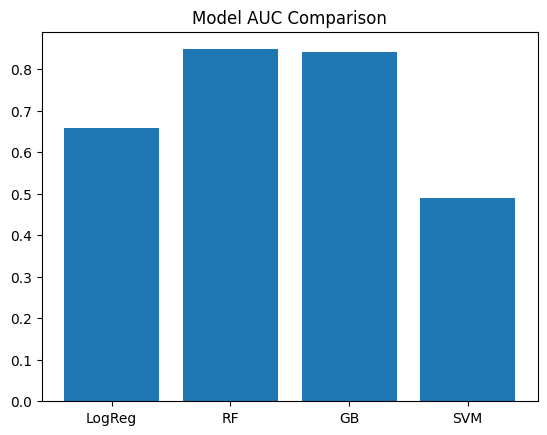

dict_keys(['LogReg', 'RF', 'GB', 'SVM'])
---------
dict_values([0.6585950198623819, 0.8477244912366344, 0.8421950749131815, 0.4884771995711739])


In [32]:

plt.bar(results.keys(),results.values())
plt.title("Model AUC Comparison")
plt.show()
print(results.keys())
print("---------")
print(results.values()) 
